<a href="https://colab.research.google.com/github/dancingdinosaur/NexoSci-project/blob/main/NexoSci_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()
import pandas as pd
# header=0 ensures the title row isn't treated as data!
df = pd.read_csv("student_lifestyle_data.csv", header=0)
df.head()

Saving student_lifestyle_data.csv to student_lifestyle_data.csv


,student_id,pre_review,screen_time,hw_hours,sleep_hours,fell_asleep_in_class,test_score
0,1,No,3.8,2.1,7.1,No,58.0
1,2,No,1.5,3.9,8.7,No,68.6
2,3,Yes,4.1,3.2,7.1,No,84.9
3,4,No,4.4,2.8,6.9,Yes,53.5
4,5,No,4.3,1.5,6.1,Yes,53.4


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   student_id            500 non-null    int64  
 1   pre_review            500 non-null    object 
 2   screen_time           500 non-null    float64
 3   hw_hours              500 non-null    float64
 4   sleep_hours           500 non-null    float64
 5   fell_asleep_in_class  500 non-null    object 
 6   test_score            498 non-null    float64
dtypes: float64(4), int64(1), object(2)
memory usage: 27.5+ KB


In [ ]:
df.describe()

,student_id,screen_time,hw_hours,sleep_hours,test_score
count,500.000000,500.000000,500.000000,500.000000,498.000000
mean,250.500000,3.722200,2.497600,7.077400,68.493775
std,144.481833,1.772922,0.897466,1.358868,10.570177
min,1.000000,0.000000,1.000000,-3.000000,45.200000
25%,125.750000,2.700000,1.700000,6.275000,60.400000
50%,250.500000,3.700000,2.500000,7.100000,68.600000
75%,375.250000,4.600000,3.300000,8.000000,76.700000
max,500.000000,26.000000,4.000000,10.900000,97.200000


In [ ]:
# 1. Drop rows with Missing Values (NaN)
df_clean = df.dropna()
# 2. Filter out impossible Outliers
# Keep only rows with sleep_hours <= 24 AND training_hours
df_clean = df_clean[(df_clean['screen_time'] <= 24) &
(df_clean['sleep_hours'] >= 0)]

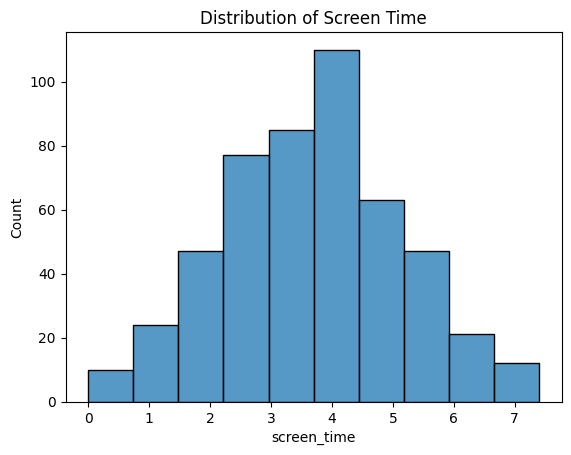

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data=df_clean, x="screen_time", bins=10)
plt.title("Distribution of Screen Time")
plt.show()

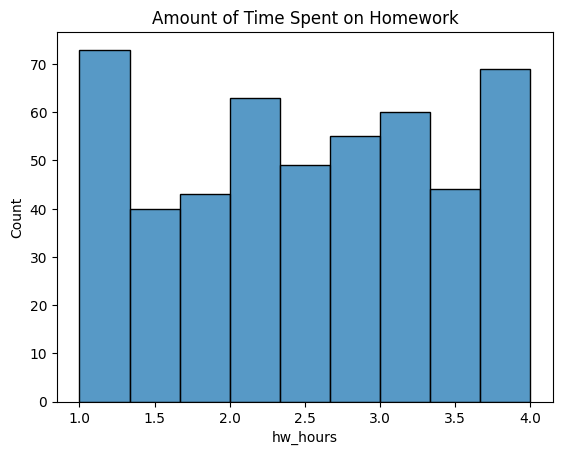

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data=df_clean, x="hw_hours", bins=9)
plt.title("Amount of Time Spent on Homework")
plt.show()

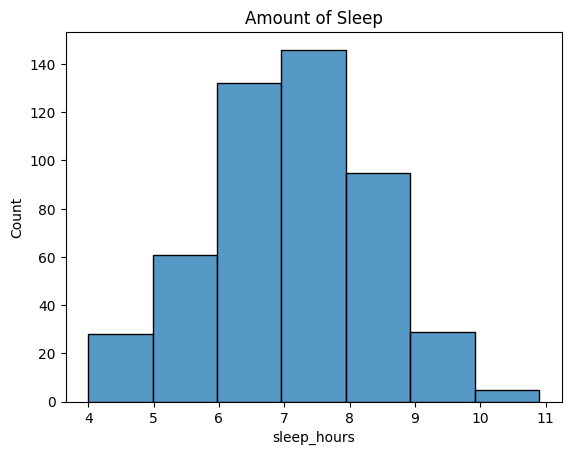

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.histplot(data=df_clean, x="sleep_hours", bins=7)
plt.title("Amount of Sleep")
plt.show()

             student_id  screen_time  hw_hours  sleep_hours  test_score
student_id         1.00        -0.03      0.04         0.04        0.04
screen_time       -0.03         1.00     -0.08        -0.92       -0.60
hw_hours           0.04        -0.08      1.00         0.08       -0.02
sleep_hours        0.04        -0.92      0.08         1.00        0.65
test_score         0.04        -0.60     -0.02         0.65        1.00


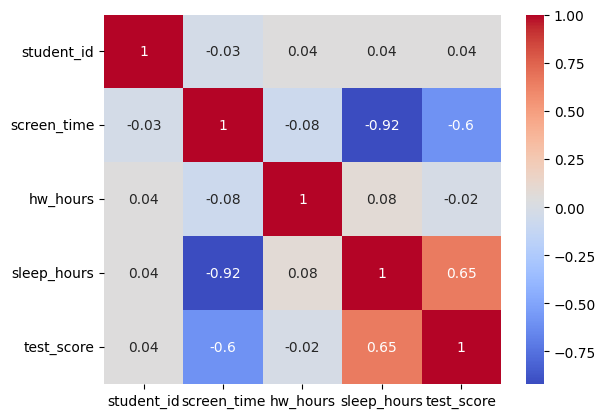

In [ ]:
corr_matrix = df_clean.corr(numeric_only=True).round(2)
print(corr_matrix)
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm")
plt.show()

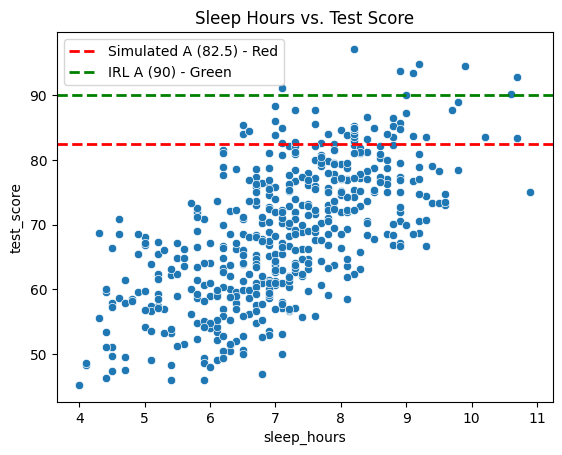

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df_clean, x="sleep_hours", y="test_score")
plt.axhline(82.5, color='red', linestyle='--', linewidth=2, label='Simulated A (82.5) - Red')
plt.axhline(90, color='green', linestyle='--', linewidth=2, label='IRL A (90) - Green')
plt.title("Sleep Hours vs. Test Score")
plt.legend()
plt.show()

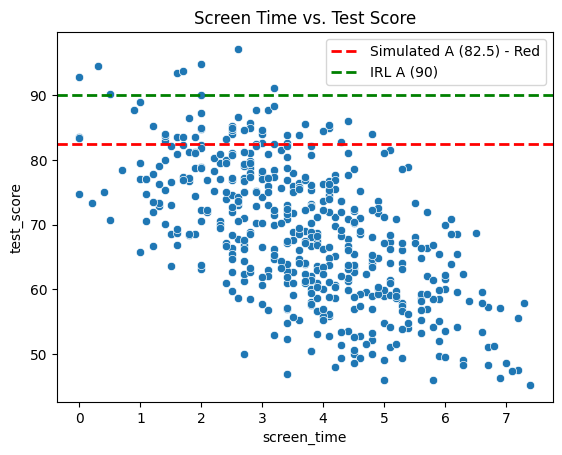

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df_clean, x="screen_time", y="test_score")
plt.axhline(82.5, color='red', linestyle='--', linewidth=2, label='Simulated A (82.5) - Red')
plt.axhline(90, color='green', linestyle='--', linewidth=2, label='IRL A (90)')
plt.title("Screen Time vs. Test Score")
plt.legend()
plt.show()

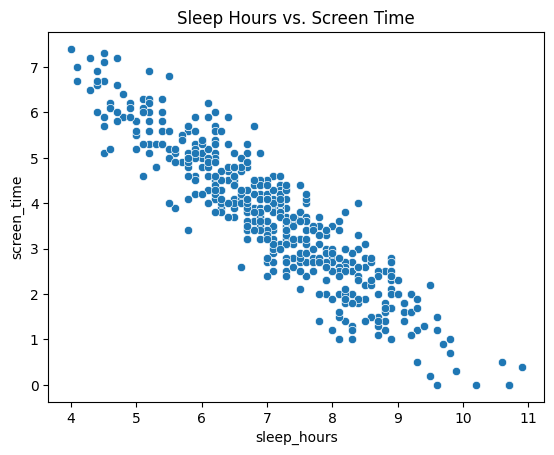

In [ ]:
sns.scatterplot(data=df_clean, x="sleep_hours",
y="screen_time")
plt.title("Sleep Hours vs. Screen Time")
plt.show()

In [ ]:
import statsmodels.api as sm
X = sm.add_constant(df_clean["hw_hours"])
Y = df_clean["test_score"]
model = sm.OLS(Y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             test_score   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.002
Method:                 Least Squares   F-statistic:                    0.2578
Date:                Mon, 16 Nov 2026   Prob (F-statistic):              0.612
Time:                        00:05:55   Log-Likelihood:                -1873.3
No. Observations:                 496   AIC:                             3751.
Df Residuals:                     494   BIC:                             3759.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         69.1879      1.414     48.926      0.0

In [ ]:
df_clean['asleep?'] = df_clean['fell_asleep_in_class'].map(
{'Yes': 1, 'No': 0})
df_clean['reviewed?'] = df_clean['pre_review'].map(
{'Yes': 1, 'No': 0})

In [ ]:
X = df_clean[["reviewed?", "sleep_hours"]]
X = sm.add_constant(X)
Y = df_clean["test_score"]
model_mult = sm.OLS(Y, X).fit()
print(model_mult.summary())

                            OLS Regression Results                            
Dep. Variable:             test_score   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     610.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          3.89e-134
Time:                        00:05:55   Log-Likelihood:                -1564.4
No. Observations:                 496   AIC:                             3135.
Df Residuals:                     493   BIC:                             3147.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          25.9456      1.456     17.821      

In [ ]:
X = df_clean[["reviewed?", "asleep?"]]
X = sm.add_constant(X)
Y = df_clean["test_score"]
model_mult = sm.OLS(Y, X).fit()
print(model_mult.summary())

                            OLS Regression Results                            
Dep. Variable:             test_score   R-squared:                       0.742
Model:                            OLS   Adj. R-squared:                  0.741
Method:                 Least Squares   F-statistic:                     710.1
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          6.74e-146
Time:                        00:05:55   Log-Likelihood:                -1537.1
No. Observations:                 496   AIC:                             3080.
Df Residuals:                     493   BIC:                             3093.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         70.2317      0.394    178.254      0.0

In [ ]:
X = df_clean[["reviewed?", "sleep_hours"]]
X = sm.add_constant(X)
Y = df_clean["test_score"]
model_mult = sm.OLS(Y, X).fit()
print(model_mult.summary())

                            OLS Regression Results                            
Dep. Variable:             test_score   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     610.6
Date:                Mon, 16 Nov 2026   Prob (F-statistic):          3.89e-134
Time:                        00:05:55   Log-Likelihood:                -1564.4
No. Observations:                 496   AIC:                             3135.
Df Residuals:                     493   BIC:                             3147.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const          25.9456      1.456     17.821      

In [ ]:
X = sm.add_constant(df_clean["sleep_hours"])
Y = df_clean["asleep?"]
model_log = sm.Logit(Y, X).fit()
print(model_log.summary())

Optimization terminated successfully.
         Current function value: 0.280455
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                asleep?   No. Observations:                  496
Model:                          Logit   Df Residuals:                      494
Method:                           MLE   Df Model:                            1
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.5937
Time:                        00:05:55   Log-Likelihood:                -139.11
converged:                       True   LL-Null:                       -342.34
Covariance Type:            nonrobust   LLR p-value:                 2.144e-90
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const          24.0135      2.392     10.038      0.000      19.325      28.702
sleep_hours    -3.4378    

Optimization terminated successfully.
         Current function value: 0.280455
         Iterations 8


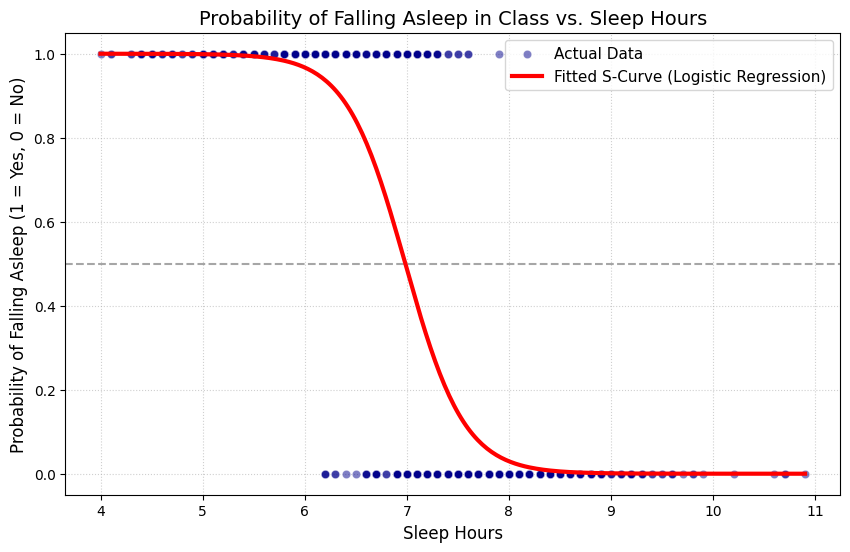

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import statsmodels.api as sm

# 1. Reload and clean the data to restore variables
df = pd.read_csv("student_lifestyle_data.csv", header=0)
df_clean = df.dropna()
df_clean = df_clean[(df_clean['screen_time'] <= 24) & (df_clean['sleep_hours'] >= 0)]
df_clean['asleep?'] = df_clean['fell_asleep_in_class'].map({'Yes': 1, 'No': 0})

# 2. Re-fit the logistic regression model
X = sm.add_constant(df_clean["sleep_hours"])
Y = df_clean["asleep?"]
model_log = sm.Logit(Y, X).fit()

# 3. Generate smooth range of sleep hours for predictions
x_range = np.linspace(df_clean['sleep_hours'].min(), df_clean['sleep_hours'].max(), 300)
x_range_const = sm.add_constant(x_range)
y_prob = model_log.predict(x_range_const)

# 4. Plot the S-curve
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='sleep_hours', y='asleep?', alpha=0.5, label='Actual Data', color='darkblue', zorder=2)
plt.plot(x_range, y_prob, color='red', linewidth=3, label='Fitted S-Curve (Logistic Regression)', zorder=3)

plt.axhline(0.5, color='gray', linestyle='--', alpha=0.7)
plt.title('Probability of Falling Asleep in Class vs. Sleep Hours', fontsize=14)
plt.xlabel('Sleep Hours', fontsize=12)
plt.ylabel('Probability of Falling Asleep (1 = Yes, 0 = No)', fontsize=12)
plt.legend(loc='best', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

The threshold score for the top 10% is: 82.45


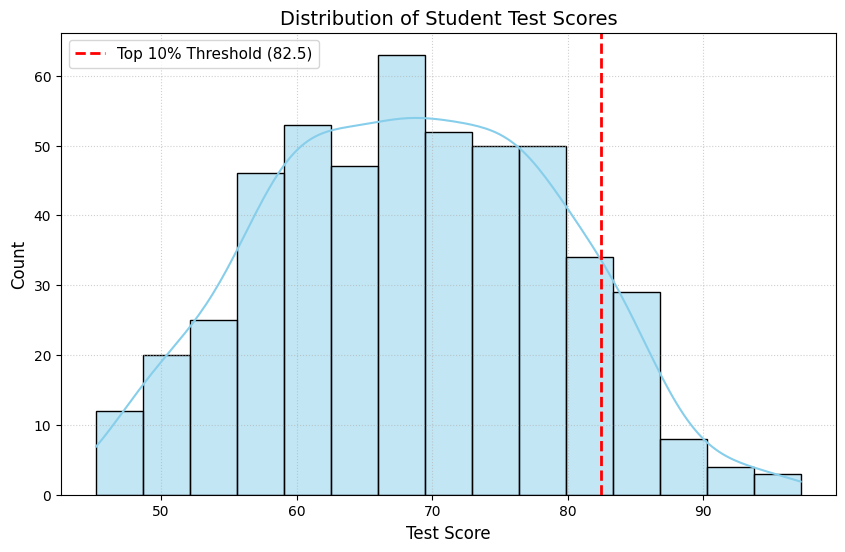

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the 90th percentile (the threshold for the top 10%)
top_10_percent_threshold = df_clean['test_score'].quantile(0.90)
print(f"The threshold score for the top 10% is: {top_10_percent_threshold:.2f}")

# Plot the test score distribution
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='test_score', bins=15, kde=True, color='skyblue')

# Add a vertical line for the top 10% threshold
plt.axvline(top_10_percent_threshold, color='red', linestyle='--', linewidth=2,
            label=f'Top 10% Threshold ({top_10_percent_threshold:.1f})')

plt.title('Distribution of Student Test Scores', fontsize=14)
plt.xlabel('Test Score', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()